# **Logistic Regression Model**

Unlike Linear Regression which is used for predicting continuous values, **Logistic Regression** is a classification algorithm used to predict the probability of a binary event (0 or 1).

**Import necessary libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
import statsmodels.api as sm
import sklearn.model_selection as model_selection

In [3]:

X = np.array([1, 2, 3, 4, 5])
Y = np.array([0, 1, 0, 1, 1])

df = pd.DataFrame({
    "hour_study": X,
    "Score": Y
})

display(df)

,hour_study,Score
0,1,0
1,2,1
2,3,0
3,4,1
4,5,1


**Build the Simple Logistic Regression model**

In [4]:
X_model = sm.add_constant(X)
logistic_model = sm.Logit(Y, X_model).fit()

print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.484393
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                    5
Model:                          Logit   Df Residuals:                        3
Method:                           MLE   Df Model:                            1
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                  0.2803
Time:                        22:09:32   Log-Likelihood:                -2.4220
converged:                       True   LL-Null:                       -3.3651
Covariance Type:            nonrobust   LLR p-value:                    0.1696
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.6486      2.806     -0.944      0.345      -8.148       2.851
x1             1.0904      0.

In [5]:

# Predicted probabilities
Y_pred = logistic_model.predict(X_model)
print(Y_pred)

[0.17391068 0.38515236 0.65083011 0.84723996 0.94286688]


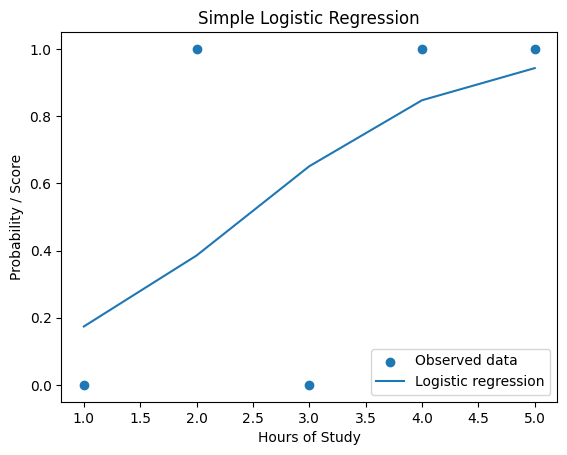

In [6]:
# Plot
plt.scatter(X, Y, label="Observed data")
plt.plot(X, Y_pred, label="Logistic regression")

plt.xlabel("Hours of Study")
plt.ylabel("Probability / Score")
plt.title("Simple Logistic Regression")
plt.legend()
plt.show()

### **Evaluation Metrics for Logistic Regression**

To evaluate our classification model's performance, we can compute metrics like accuracy, precision, recall, F1-score, and display a confusion matrix.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predicted probabilities
Y_pred = logistic_model.predict(X_model)

# Convert probabilities to classes
Y_pred_class = (Y_pred >= 0.5).astype(int)

print("Predicted probabilities:", Y_pred)
print("Predicted classes:", Y_pred_class)

#  Accuracy
accuracy = accuracy_score(Y, Y_pred_class)
print("Accuracy:", accuracy)

#  Precision
precision = precision_score(Y, Y_pred_class)
print("Precision:", precision)

#  Recall
recall = recall_score(Y, Y_pred_class)
print("Recall:", recall)

#  F1-score
f1 = f1_score(Y, Y_pred_class)
print("F1-score:", f1)

Predicted probabilities: [0.17391068 0.38515236 0.65083011 0.84723996 0.94286688]
Predicted classes: [0 0 1 1 1]
Accuracy: 0.6
Precision: 0.6666666666666666
Recall: 0.6666666666666666
F1-score: 0.6666666666666666



# **Multiple Logistic Regression**


Let's apply Multiple logistic regression to the real dataset: `/content/Multiple_logistic_Regression.csv`.
 We will load the data, define a target variable, preprocess the features, fit the model, and evaluate it.

In [8]:
from google.colab import files
upload=files.upload()

Saving Multiple_logistic_Regression.csv to Multiple_logistic_Regression.csv


In [9]:
import pandas as pd


In [25]:
df=pd.read_csv("Multiple_logistic_Regression.csv",sep=";")
df.head()



,Study_Hours,Attendance_Percent,Assignments_Completed,Previous_Score,Sleep_Hours,Pass
0,9.87,70.7,10.0,66.7,7.1,1
1,11.63,76.7,9.5,64.4,6.2,1
2,7.49,89.9,8.9,57.8,7.1,1
3,1.17,76.8,7.3,60.4,5.1,0
4,3.61,82.0,6.4,71.2,6.3,1


In [26]:
print(df.shape)

(1000, 6)


In [11]:
x=df[['Study_Hours','Attendance_Percent','Assignments_Completed','Previous_Score','Sleep_Hours']]
y=df['Pass']


In [12]:
x.head()


,Study_Hours,Attendance_Percent,Assignments_Completed,Previous_Score,Sleep_Hours
0,9.87,70.7,10.0,66.7,7.1
1,11.63,76.7,9.5,64.4,6.2
2,7.49,89.9,8.9,57.8,7.1
3,1.17,76.8,7.3,60.4,5.1
4,3.61,82.0,6.4,71.2,6.3


In [13]:
y.head()

,Pass
0,1
1,1
2,1
3,0
4,1


**Build the Multiple Logistic Regression model**

In [14]:
import statsmodels.api as sm
x_model=sm.add_constant(x)
log_model=sm.Logit(y,x_model).fit()
print(log_model.summary())

Optimization terminated successfully.
         Current function value: 0.146480
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                   Pass   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      994
Method:                           MLE   Df Model:                            5
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                  0.2729
Time:                        22:10:22   Log-Likelihood:                -146.48
converged:                       True   LL-Null:                       -201.45
Covariance Type:            nonrobust   LLR p-value:                 4.222e-22
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   -12.6900      2.158     -5.881      0.000     -16.919      -8.

In [15]:
intercept = log_model.params['const']
params = log_model.params[1:]  #
feature_names = x.columns     #
equation_terms = [f"({params[i]:.4f} * {feature_names[i]})" for i in range(len(params))]
equation_str = f"Log-Odds = {intercept:.4f} + " + " + ".join(equation_terms)

print("\n" + "="*80)
print("(Log-Odds Equation):")
print("="*80)
print(equation_str)
print("="*80)


(Log-Odds Equation):
Log-Odds = -12.6900 + (0.4496 * Study_Hours) + (0.0451 * Attendance_Percent) + (0.4870 * Assignments_Completed) + (0.0382 * Previous_Score) + (0.6066 * Sleep_Hours)


/tmp/ipykernel_2156/920913369.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  equation_terms = [f"({params[i]:.4f} * {feature_names[i]})" for i in range(len(params))]


In [16]:
Y_pred=log_model.predict(x_model)
print(Y_pred.head())

0    0.998719
1    0.998935
2    0.996241
3    0.563229
4    0.907829
dtype: float64


In [17]:
import numpy as np
Y_pred_class=np.where(Y_pred>0.5,1,0)
print(Y_pred_class)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 1 1 1 1 1 1 1 1 

### **Evaluation Metrics for Multiple Logistic Regression**

To evaluate our classification model's performance, we can compute metrics like accuracy, precision, recall, F1-score, and display a confusion matrix.

In [18]:
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
#   Calculeted  confusion matrix
confussion_matrix = metrics.confusion_matrix(y, Y_pred_class)
print("Confusion Matrix:\n", confussion_matrix)

Confusion Matrix:
 [[  4  47]
 [  3 946]]


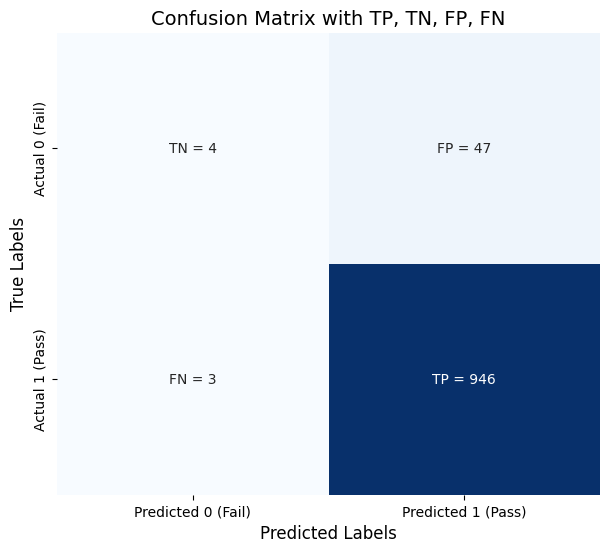

In [20]:
# Extracting   ( TN, FP, FN, TP)
TN = confussion_matrix[0, 0]
FP = confussion_matrix[0, 1]
FN = confussion_matrix[1, 0]
TP = confussion_matrix[1, 1]

labels = np.array([
    [f"TN = {TN}", f"FP = {FP}"],
    [f"FN = {FN}", f"TP = {TP}"]
])

# plot confusion matrix
plt.figure(figsize=(7, 6))
sns.heatmap(confussion_matrix, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0 (Fail)', 'Predicted 1 (Pass)'],
            yticklabels=['Actual 0 (Fail)', 'Actual 1 (Pass)'])

plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.title('Confusion Matrix with TP, TN, FP, FN', fontsize=14)
plt.show()

In [21]:
accuracy=metrics.accuracy_score(y,Y_pred_class)
print("accuracy:",accuracy)

accuracy: 0.95


In [22]:
recall=metrics.recall_score(y,Y_pred_class)
print("recall:",recall)


recall: 0.9968387776606955


In [23]:
f_squrea=metrics.f1_score(y,Y_pred_class)
print("f_squrea:",f_squrea)

f_squrea: 0.9742533470648815
